# 11 · Demo: una solicitud de crédito de punta a punta con un agente de IA

Este notebook recorre una solicitud real de Lending Club (jul–dic 2015, nunca vista por los modelos) por todo el sistema, a partir de una **traza guardada**: no necesita API key ni cuesta nada.

| Paso | Quién | Qué hace |
|---|---|---|
| 1 | 3 especialistas Claude en paralelo | Riesgo (PD + razones SHAP), economía (prepago y pérdida) y cupo/pricing (monto, tasas, estrés). Cada número sale de una herramienta, que es código sobre los modelos del repo |
| 2 | Comité IA | Aplica la política y decide aprobar, rechazar o contraofertar; redacta el memo |
| 3 | Reglas duras (código) | Cuota ≤ 20% del ingreso y ROI esperado ≥ 0% |
| 4 | Auditor IA | Verifica números y política; si falla, devuelve el caso al comité |

Agente: Claude Haiku 5.5 (versión v2 de los prompts). Código: `src/credit_lab/agente.py`. Evals: `src/credit_lab/evals.py`.

In [1]:
import json
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

pd.set_option("display.float_format", "{:,.4f}".format)
AZUL_CLARO, AZUL_MEDIO, AZUL = "#cde2fb", "#86b6ef", "#2a78d6"
TINTA, TINTA_2, GRILLA = "#0b0b0b", "#52514e", "#e5e4df"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRILLA, "axes.labelcolor": TINTA_2, "xtick.color": TINTA_2,
    "ytick.color": TINTA_2, "axes.grid": True, "grid.color": GRILLA, "grid.linewidth": 0.6,
    "axes.titlecolor": TINTA, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

EVALS = Path("../evals/agente")
CASO, VERSION = "c10", "v2"
traza = json.loads((EVALS / "claude-haiku-5-5" / VERSION / "traces" / f"{CASO}.json").read_text(encoding="utf-8"))
caso = {x["id"]: x for x in json.loads((EVALS / "casos.json").read_text(encoding="utf-8"))}[CASO]
pasos = {(p["nodo"], p["intento"]): p["contenido"] for p in traza["historial"]}
pd.Series(caso["solicitud"]).to_frame("solicitud")

,solicitud
monto pedido (USD),"15,000.0000"
tasa ofrecida por Lending Club (%),9.1700
ingreso anual (USD),"60,000.0000"
propósito,debt_consolidation
deuda / ingreso (%),18.3400
FICO,660.0000
antigüedad laboral,3 years
vivienda,RENT
uso de tarjetas (%),29.4000
consultas últimos 6 meses,1.0000


## 1. Los especialistas (en paralelo)

In [2]:
for nombre in ["riesgo", "economia", "cupo"]:
    e = pasos[(nombre, 1)]
    display(Markdown(f"### Especialista de {nombre}\n\n**Herramientas que llamó:** "
                     + ", ".join(f"`{h['herramienta']}`" for h in e["herramientas"])))
    display(Markdown(e["analisis"]))

### Especialista de riesgo

**Herramientas que llamó:** `consultar_riesgo`

**Señal final: desfavorable.**

La PD del modelo campeón (LightGBM recalibrado) es **22,76%**, frente a un promedio de cartera de **12,88%**, es decir, casi el doble del riesgo medio.

**Qué sube el riesgo:**
- **FICO de 662** (punto medio del rango): es el factor más pesado, con una contribución logit de +0,377.
- **Vivienda en alquiler (RENT):** +0,105.
- **50% de las tarjetas con uso superior al 75%:** +0,074.

**Qué lo mitiga:**
- **Antigüedad de la cuenta rotativa más antigua de 248 meses:** −0,136.
- **76,7% de las cuentas nunca en mora:** −0,088.

El perfil tiene historial de pago razonable y una cuenta antigua, pero el puntaje FICO moderado y la alta utilización de tarjetas en la mitad de los plásticos empujan la PD muy por encima de la media. Si se decide avanzar, conviene revisar la capacidad de pago y la tasa frente a este nivel de riesgo.

### Especialista de economia

**Herramientas que llamó:** `consultar_economia`, `simular_oferta`

**Señal final: desfavorable**

**Hallazgos clave (a 9,17 %, USD 15.000):**
- **Escenario bueno:** rendimiento de 12,06 %.
- **Escenario malo:** pérdida económica de -32,51 %.
- **Probabilidad de incumplimiento (PD):** 22,76 %.
- **ROI esperado:** 1,91 %, con utilidad esperada de USD 287,13.
- **Prepago:** probabilidad de 55,87 % de pagar antes del mes 30; mes esperado de pago, 25,09.
- **Capacidad de pago:** cuota/ingreso de 9,56 %, dentro del límite.
- **Tasa de mercado estimada:** 11,62 %. La oferta está más de 1 punto por debajo, por lo que la herramienta la marca fuera de rango y no hay evidencia histórica que la respalde.

**Lectura:** la capacidad de pago alcanza, pero el retorno esperado es bajo para el riesgo que implica una PD de 22,76 % y una pérdida de -32,51 % en el escenario malo. Con una tasa tan por debajo del mercado, el resultado depende de supuestos poco respaldados por datos históricos.

### Especialista de cupo

**Herramientas que llamó:** `consultar_cupo_pricing`, `simular_oferta`, `simular_oferta`

**Hallazgos clave**

- **Oferta actual (9,17%)**: ROI esperado de 1,91%, por debajo del objetivo de 4%. PD de 22,76%. Utilidad esperada de USD 287,13. Está 2,45 pts por debajo de la tasa de mercado (11,62%), así que queda **fuera de rango** y no tiene respaldo histórico.
- **Tasa de equilibrio (ROI ≥ 0%)**: 7,5%.
- **Tasa sugerida (ROI ≥ 4%)**: 11,5%. Dentro de rango.
- **Oferta alternativa (11,5%)**: ROI de 4,35%, utilidad de USD 652,46, cuota/ingreso de 9,89%, cumple capacidad de pago y no está fuera de rango.
- **Cupo máximo**: USD 23.000. El monto pedido de USD 15.000 está dentro.
- **Estrés**: la herramienta devolvió los mismos valores de equilibrio (7,5%) y sugerida (11,5%). No aplica un cambio visible en la PD.

**Mejor oferta:** USD 15.000 a 11,5%. Mejora el ROI en más de 2 pts frente a la tasa original y sale del rango no respaldado.

**Señal final: neutral.** El perfil es viable con la tasa sugerida, pero la oferta original es desfavorable por bajo retorno y falta de evidencia.

Lo que devolvió la herramienta de cupo y pricing: los números que el comité y el auditor pueden verificar.

In [3]:
cupo = pasos[("cupo", 1)]["herramientas"][0]["salida"]
claves = ["monto_pedido", "tasa_ofrecida", "tasa_mercado", "pd", "roi_esperado", "cuota_ingreso",
          "monto_maximo", "tasa_equilibrio", "tasa_sugerida", "tasa_sugerida_estres", "sugerida_fuera_de_rango"]
pd.Series({k: cupo[k] for k in claves}).to_frame("consultar_cupo_pricing")

,consultar_cupo_pricing
monto_pedido,"15,000.0000"
tasa_ofrecida,9.1700
tasa_mercado,11.6167
pd,0.2276
roi_esperado,0.0191
cuota_ingreso,0.0956
monto_maximo,"23,000.0000"
tasa_equilibrio,7.5000
tasa_sugerida,11.5000
tasa_sugerida_estres,11.5000


## 2. Comité y auditor

In [4]:
filas = []
for (nodo, intento), x in pasos.items():
    if nodo == "comite":
        filas.append({"intento": intento, "nodo": "comité", "resultado": f"{x['decision']} · USD {x['monto']:,.0f} · {x['tasa']}%"})
    if nodo == "auditor":
        filas.append({"intento": intento, "nodo": "auditor", "resultado": "aprobado" if x["aprobado"] else "rechazado",
                      "violaciones de reglas duras": len(x["violaciones"]), "hallazgos": len(x["hallazgos"])})
pd.DataFrame(filas).fillna("")

C:\Users\Neider Olaya\AppData\Local\Temp\ipykernel_36364\1647885338.py:8: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  pd.DataFrame(filas).fillna("")


,intento,nodo,resultado,violaciones de reglas duras,hallazgos
0,1,comité,"contraoferta · USD 15,000 · 11.5%",,
1,1,auditor,aprobado,0.0000,5.0000


## 3. El memo final

In [5]:
display(Markdown(traza["final"]["memo"]))

## Resumen
La solicitud de 15000 a 9.17% no cumple la política de aprobación porque el ROI esperado es 1.91%, por debajo de 4%. Se propone una contraoferta de 15000 a 11.5%.

## Decisión
Contraoferta por 15000 a una tasa de 11.5%. A esta tasa el ROI esperado es 4.35%, la utilidad esperada es 652.46 y la cuota es 9.89% del ingreso, dentro del límite de 20%. El monto pedido cumple el criterio de la opción a de la política, por lo que no aplica el monto máximo.

## Riesgo
El especialista de riesgo informa una PD de 22.76% frente a un promedio de cartera de 12.88%. Atribuye el mayor aporte al puntaje FICO de 662 (punto medio del rango), seguido del tipo de vivienda RENT y de 50% de tarjetas con uso superior al 75%. Como factores que mitigan, menciona una antigüedad de 248 meses en la cuenta rotativa más antigua y 76.70% de cuentas nunca en mora. Su señal final es desfavorable.

## Economía
El especialista de economía informa, a la tasa original de 9.17%, un escenario bueno de 12.06% y un escenario malo de -32.51%, con una probabilidad de prepago antes del mes 30 de 55.87% y un mes esperado de pago de 25.09. Su señal final es desfavorable. La simulación a 11.5% no aparece marcada como fuera de rango.

## Cupo y precio
La tasa de equilibrio (ROI mayor o igual a 0%) es 7.5% y la tasa sugerida (ROI mayor o igual a 4%) es 11.5%. La tasa de mercado estimada es 11.62% y el cupo máximo es 15000 o más, según la herramienta: 23000. El especialista de cupo da una señal neutral: la oferta original queda desfavorable por bajo retorno y por estar fuera de rango, y la tasa sugerida es viable.

## Alertas
- La oferta original de 9.17% está fuera de rango, sin evidencia histórica que la respalde.
- La herramienta de estrés devolvió los mismos valores de tasa de equilibrio (7.5%) y tasa sugerida (11.5%); no cambia la decisión.
- La tasa de mercado se estima para el perfil y el monto, así que cambia si cambia el monto.

## 4. ¿Qué pasó en la realidad? (el agente nunca lo vio)

In [6]:
fila = next(json.loads(l) for l in (EVALS / "claude-haiku-5-5" / VERSION / "results.jsonl").read_text(encoding="utf-8").splitlines()
            if json.loads(l)["id"] == CASO)
pd.Series({"decisión del agente": fila["decision_agente"], "decisión de la política del motor": fila["decision_motor"],
           "resultado real": "malo" if fila["malo_real"] else "bueno", "ROI real": f"{fila['roi_real']:.1%}",
           "costo del agente (USD)": f"{fila['cost_usd']:.4f}", "latencia (s)": f"{fila['latency_s']:.0f}",
           "juez Opus 5.5": f"{fila['grade']['juez']:.0%}"}).to_frame(CASO)

,c10
decisión del agente,contraoferta
decisión de la política del motor,contraoferta
resultado real,bueno
ROI real,13.2%
costo del agente (USD),0.0067
latencia (s),57
juez Opus 5.5,100%


## 5. ¿Qué tan bien decide en general? Evals con 30 casos

30 préstamos estratificados por la decisión de la política del motor y el resultado real. v0 y v1 son pilotos de 5 casos; v2 corrió los 30 (decisión 019).

,v0 (5 casos),v1 (5 casos),v2 (30 casos)
concordancia,20%,100%,83%
reglas_ok,100%,100%,100%
fidelidad,93%,93%,94%
auditoria_1er_intento,0%,80%,93%
juez,56%,76%,97%
costo por solicitud (USD),0.0112,0.0083,0.0072


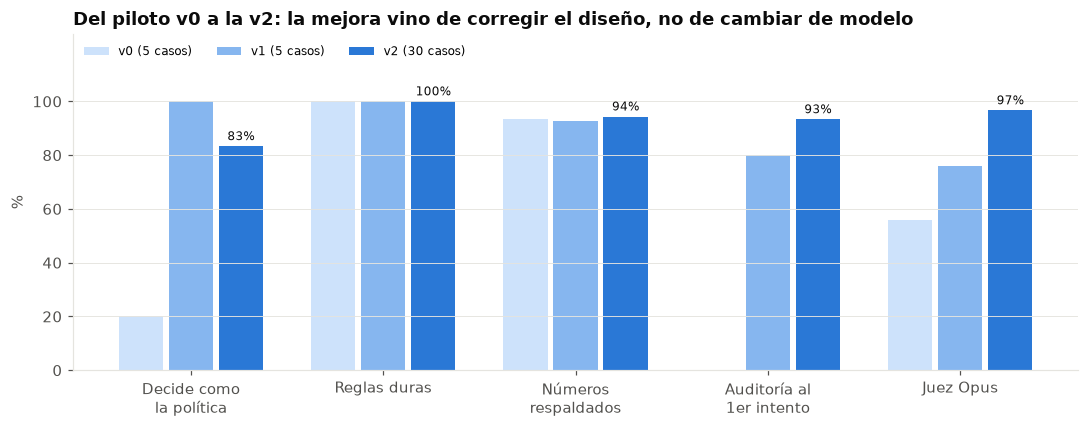

In [7]:
metricas = {"concordancia": "Decide como\nla política", "reglas_ok": "Reglas duras", "fidelidad": "Números\nrespaldados",
            "auditoria_1er_intento": "Auditoría al\n1er intento", "juez": "Juez Opus"}
resumen = {}
for v in ["v0", "v1", "v2"]:
    filas = [json.loads(l) for l in (EVALS / "claude-haiku-5-5" / v / "results.jsonl").read_text(encoding="utf-8").splitlines() if l.strip()]
    df = pd.json_normalize(filas)
    resumen[f"{v} ({len(df)} casos)"] = {m: df[f"grade.{m}"].mean() for m in metricas} | {"costo por solicitud (USD)": df["cost_usd"].mean()}
tabla = pd.DataFrame(resumen)

fig, ax = plt.subplots(figsize=(10, 4))
x = range(len(metricas))
ancho = 0.26
for k, (version, color) in enumerate(zip(tabla.columns, [AZUL_CLARO, AZUL_MEDIO, AZUL])):
    valores = [tabla.loc[m, version] * 100 for m in metricas]
    barras = ax.bar([i + (k - 1) * ancho for i in x], valores, ancho - 0.03, color=color, label=version)
    if k == 2:
        ax.bar_label(barras, fmt="%.0f%%", fontsize=8, color=TINTA, padding=2)
ax.set_xticks(list(x), list(metricas.values()))
ax.set_ylim(0, 125)
ax.set_yticks(range(0, 101, 20))
ax.set_ylabel("%")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, fontsize=8, loc="upper left", ncol=3)
ax.set_title("Del piloto v0 a la v2: la mejora vino de corregir el diseño, no de cambiar de modelo")
fig.tight_layout()
tabla.style.format("{:.0%}").format("{:.4f}", subset=pd.IndexSlice[["costo por solicitud (USD)"], :])

---
## ✍️ Conclusiones de Neider

1. **El sistema decide de punta a punta sin humanos y es auditable.** Cada número del memo sale de una herramienta sobre los modelos; el comité decide con la política y un auditor de IA lo revisa. En esta solicitud contraofertó una tasa más alta que la de Lending Club, y el préstamo se pagó con ROI real de 13,2%.
2. **La mejora vino del diseño, no del modelo.** De v0 a v2 la concordancia con la política pasó de 20% a 83% y la auditoría al primer intento de 0% a 93% con el mismo Haiku: dar a todos la misma política y los mismos datos importó más que el modelo.
3. **Es barato.** Con Haiku 5.5 cada solicitud cuesta USD 0,007 y tarda ~50 s; la comparación con Sonnet queda pendiente.